# Lab 04-10 · Introduction to Quantum Mechanics

Companion to chapter [04-10](../../chapters/04-10-intro-quantum-mechanics.md). Handout: [README.md](README.md).

Cells marked **🔮 Predict** ask for a prediction *before* running. Part 5 uses random numbers with seed 2026.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal
from scipy.sparse import diags
from scipy.sparse.linalg import splu
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
h, e, me = 6.62607015e-34, 1.602176634e-19, 9.1093837139e-31
hbar = h / (2 * math.pi)
rng = np.random.default_rng(2026)

## Part 1 — Schrödinger's equation as a matrix

On a grid of spacing $\Delta x$, $-\frac{\hbar^2}{2m}\psi'' \approx -\frac{\hbar^2}{2m}\frac{\psi_{i+1} - 2\psi_i + \psi_{i-1}}{\Delta x^2}$, so the equation becomes a tridiagonal matrix eigenproblem (02-08): the eigenvalues are the allowed energies.

**🔮 Predict:** how many bound states does a well 1 eV deep and 2 nm wide hold for an electron?

infinite well, 1 nm: E1..E4 = [0.3757 1.5026 3.3809 6.0105] eV;  formula n^2 h^2/(8 m L^2) = [0.376  1.5041 3.3843 6.0165]
finite well: 4 bound states at [0.06554 0.25895 0.56725 0.9382 ] eV


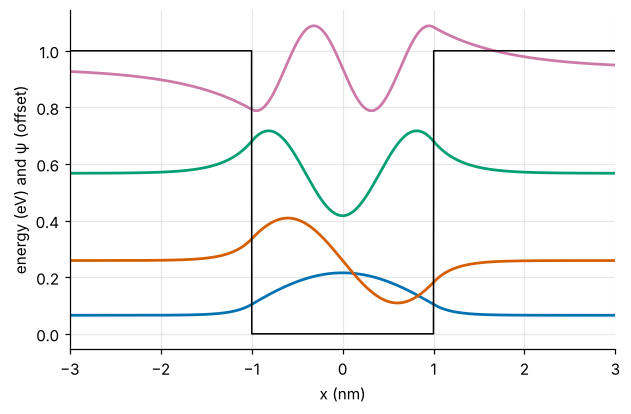

In [2]:
def solve(V_of_x, L, N=4000, Emax=None, m=me):
    x = np.linspace(-L / 2, L / 2, N); dx = x[1] - x[0]
    t = hbar**2 / (2 * m * dx**2)
    V = V_of_x(x) * e
    if Emax is None:
        w, v = eigh_tridiagonal(2 * t + V, -t * np.ones(N - 1), select="i", select_range=(0, 3))
    else:
        w, v = eigh_tridiagonal(2 * t + V, -t * np.ones(N - 1), select="v", select_range=(-1e-30, Emax * e))
    return x, w / e, v
# infinite well 1 nm wide: walls are the grid ends
x, E, v = solve(lambda x: 0 * x, 1e-9)
print("infinite well, 1 nm: E1..E4 =", np.round(E, 4), "eV;  formula n^2 h^2/(8 m L^2) =", np.round([n*n*h**2/(8*me*1e-18)/e for n in (1,2,3,4)], 4))
# finite well: 1 eV deep, 2 nm wide, in a 10 nm box
x, Ef, vf = solve(lambda x: np.where(np.abs(x) < 1e-9, 0.0, 1.0), 10e-9, Emax=0.999)
print(f"finite well: {len(Ef)} bound states at", np.round(Ef, 5), "eV")
for i in range(len(Ef)):
    plt.plot(x * 1e9, Ef[i] + 0.15 * vf[:, i] / np.abs(vf[:, i]).max())
plt.plot(x * 1e9, np.where(np.abs(x) < 1e-9, 0, 1), "k", lw=1)
plt.xlim(-3, 3); plt.xlabel("x (nm)"); plt.ylabel("energy (eV) and ψ (offset)"); plt.show()

The infinite well matches $n^2h^2/(8mL^2)$ to about 0.1% (the grid's error); the finite well holds four bound states, each lower than its infinite-well counterpart because the wavefunction leaks into the walls (the box is effectively wider).

## Part 2 — Tunneling by matching boundary conditions

For a piecewise-constant potential, ψ is a sum of $e^{\pm ikx}$ (or $e^{\pm\kappa x}$) in each region; continuity of ψ and ψ′ at each boundary links neighbouring regions by a 2×2 matrix. Chaining the matrices handles any profile approximated by steps, including a barrier tilted by an electric field.

**🔮 Predict:** does the step-matrix method reproduce the exact rectangular-barrier formula? How strongly does a tilted barrier's transmission depend on field?

In [3]:
def transmission(E_eV, edges, V_eV, m=me):
    # regions: left lead (V=0), then steps with potentials V_eV between edges, then right lead (V=0)
    Vs = [0.0] + list(V_eV) + [0.0]
    ks = [np.sqrt(2 * m * (E_eV - Vr) * e + 0j) / hbar for Vr in Vs]
    M = np.eye(2, dtype=complex)
    for j, xb in enumerate(edges):
        k1, k2 = ks[j], ks[j + 1]
        A = np.array([[np.exp(1j * k1 * xb), np.exp(-1j * k1 * xb)], [1j * k1 * np.exp(1j * k1 * xb), -1j * k1 * np.exp(-1j * k1 * xb)]])
        B = np.array([[np.exp(1j * k2 * xb), np.exp(-1j * k2 * xb)], [1j * k2 * np.exp(1j * k2 * xb), -1j * k2 * np.exp(-1j * k2 * xb)]])
        M = np.linalg.solve(B, A) @ M
    t = 1 / M[1, 1] * np.linalg.det(M)      # with no wave incoming from the right
    t = (M[0, 0] * M[1, 1] - M[0, 1] * M[1, 0]) / M[1, 1]
    return abs(t) ** 2 * (ks[-1].real / ks[0].real)
def t_exact(E, V0, d, m=me):
    k = math.sqrt(2 * m * (V0 - E) * e) / hbar
    return 1 / (1 + V0**2 * math.sinh(k * d) ** 2 / (4 * E * (V0 - E)))
for d in (1.0e-9, 1.2e-9):
    print(f"d = {d*1e9:.1f} nm: step-matrix {transmission(1.0, [0, d], [3.1]):.4e}, exact formula {t_exact(1.0, 3.1, d):.4e}")
# a field-tilted (triangular) barrier, phi = 3.1 eV above the electron, effective mass 0.5 m0
for F in (7e8, 10e8):          # V/m (7 and 10 MV/cm)
    width = 3.1 / F             # where the tilted barrier falls back to the electron's energy
    xs = np.linspace(0, width, 801)
    Vsteps = 1.0 + 3.1 - F * 0.5 * (xs[1:] + xs[:-1])
    print(f"field {F/1e8:.0f} MV/cm: barrier {width*1e9:.2f} nm wide, T = {transmission(1.0, list(xs), list(Vsteps), m=0.5*me):.3e}")

d = 1.0 nm: step-matrix 1.2447e-06, exact formula 1.2447e-06
d = 1.2 nm: step-matrix 6.3878e-08, exact formula 6.3878e-08
field 7 MV/cm: barrier 4.43 nm wide, T = 3.771e-16
field 10 MV/cm: barrier 3.10 nm wide, T = 8.259e-12


The step method matches the exact formula. Under a strong field the barrier becomes a triangle whose width shrinks as $1/F$, so transmission rises steeply with field: Fowler–Nordheim tunneling, the write mechanism of flash. (Real devices need the measured barrier height, effective mass and image-force lowering, so treat these numbers as the trend, not a device model.)

## Part 3 — A wavepacket meets a barrier

Evolve a Gaussian packet with the time-dependent Schrödinger equation (Crank–Nicolson steps, which conserve probability) and watch it split.

**🔮 Predict:** a 0.5 eV packet hits a 1 eV, 0.5 nm barrier. Roughly what fraction gets through?

transmitted probability 0.102; plane-wave T at 0.5 eV = 0.101; total probability 1.000000


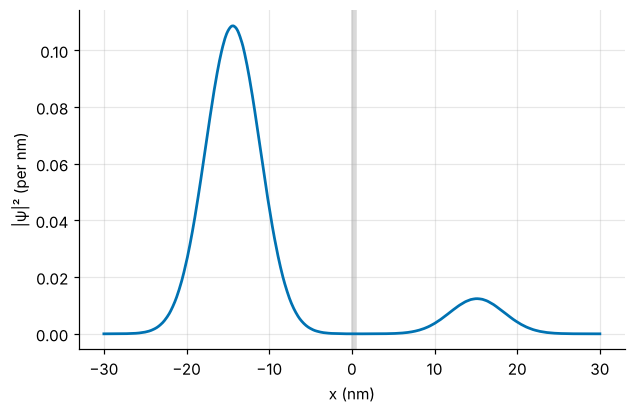

In [4]:
N, L = 3000, 60e-9
x = np.linspace(-L / 2, L / 2, N); dx = x[1] - x[0]
V = np.where((x > 0) & (x < 0.5e-9), 1.0, 0.0) * e
E0, sigma, x0 = 0.5, 3e-9, -15e-9
k0 = math.sqrt(2 * me * E0 * e) / hbar
psi = np.exp(-((x - x0) ** 2) / (4 * sigma**2) + 1j * k0 * x)
psi /= np.sqrt(np.sum(abs(psi) ** 2) * dx)
dt = 0.5e-16
t = hbar**2 / (2 * me * dx**2)
Hd = 2 * t + V
A = diags([np.full(N - 1, -t * 1j * dt / (2 * hbar)), 1 + 1j * dt / (2 * hbar) * Hd, np.full(N - 1, -t * 1j * dt / (2 * hbar))], [-1, 0, 1], format="csc")
Bm = diags([np.full(N - 1, t * 1j * dt / (2 * hbar)), 1 - 1j * dt / (2 * hbar) * Hd, np.full(N - 1, t * 1j * dt / (2 * hbar))], [-1, 0, 1], format="csc")
lu = splu(A)
v_group = hbar * k0 / me
steps = int(30e-9 / v_group / dt)
for n in range(steps):
    psi = lu.solve(Bm @ psi)
P_trans = np.sum(abs(psi[x > 0.5e-9]) ** 2) * dx
print(f"transmitted probability {P_trans:.3f}; plane-wave T at 0.5 eV = {t_exact(0.5, 1.0, 0.5e-9):.3f}; total probability {np.sum(abs(psi)**2)*dx:.6f}")
plt.plot(x * 1e9, abs(psi) ** 2 * 1e-9); plt.axvspan(0, 0.5, color="0.85")
plt.xlabel("x (nm)"); plt.ylabel("|ψ|² (per nm)"); plt.show()

About a tenth of the packet tunnels, close to the plane-wave transmission at its central energy (the packet contains a spread of energies; higher ones tunnel more easily and lower ones less, nearly cancelling here). Total probability stays 1: the electron is never lost, only split into "transmitted" and "reflected" possibilities until it is detected.

## Part 4 — The photoelectric line

Fit the stopping voltages of Problem 04-10.3.

**🔮 Predict:** how close to the true $h$ does a two-point fit get with millivolt-rounded data?

In [5]:
c = 299792458.0
lam = np.array([450e-9, 365e-9]); Vs = np.array([0.605, 1.247])
slope, icpt = np.polyfit(c / lam, Vs, 1)
print(f"h from the fit = {slope*e:.4e} J s (exact {h:.4e});  work function = {-icpt:.3f} eV")

h from the fit = 6.6300e-34 J s (exact 6.6261e-34);  work function = 2.152 eV


## Part 5 — Measuring qubits

Sample 1000 measurements of the state $\tfrac12|0\rangle + \tfrac{\sqrt3}{2}i|1\rangle$ (Problem 04-10.13), repeat the experiment 2000 times, and look at the spread.

**🔮 Predict:** the standard deviation of the count of 1s.

mean count of 1s 749.7 (expected 750); standard deviation 13.90 (expected 13.69)


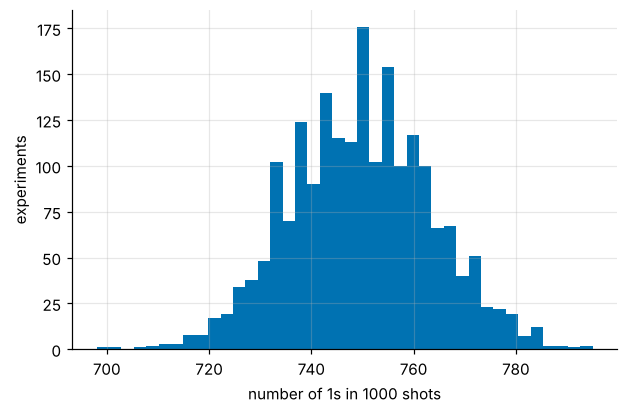

In [6]:
amps = np.array([0.5, 1j * math.sqrt(3) / 2])
p1 = abs(amps[1]) ** 2
counts = rng.binomial(1000, p1, size=2000)
print(f"mean count of 1s {counts.mean():.1f} (expected 750); standard deviation {counts.std():.2f} (expected {math.sqrt(1000*p1*(1-p1)):.2f})")
plt.hist(counts, bins=40); plt.xlabel("number of 1s in 1000 shots"); plt.ylabel("experiments"); plt.show()

## Your turn

1. In Part 1, make the finite well 0.5 nm wide. How many bound states remain? (A one-dimensional well always keeps at least one.)
2. In Part 3, lower the packet's energy to 0.3 eV. How does the transmitted fraction change, and why is it smaller than the plane-wave value at 0.3 eV would suggest from Part 2's formula alone?